### Designed by Dev Patel

In [1]:
import os
import torch
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, random_split, Dataset
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve

In [2]:
base_image_directory = "/red/ruogu.fang/share/UKB/data/Eye"
base_csv_path = "/blue/ruogu.fang/pateld3/combined_selected_images.csv"

df = pd.read_csv(base_csv_path)
df['image_path'] = df.apply(
    lambda row: f"{base_image_directory}/{row['image']}/{row['subject_id']}_{row['image'][:5]}_0_0.png",
    axis=1
)

df = df.drop(columns=['image'])

# Shuffle the dataframe
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df.head(5)

,subject_id,disease,image_path
0,2174634,1,/red/ruogu.fang/share/UKB/data/Eye/21016_fundu...
1,2294329,0,/red/ruogu.fang/share/UKB/data/Eye/21015_fundu...
2,5435256,0,/red/ruogu.fang/share/UKB/data/Eye/21015_fundu...
3,5107618,1,/red/ruogu.fang/share/UKB/data/Eye/21015_fundu...
4,5786592,1,/red/ruogu.fang/share/UKB/data/Eye/21016_fundu...


In [3]:
class UKBImageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]['image_path']
        label = self.df.iloc[idx]['disease']
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

In [4]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.6218, 0.3026, 0.1039],
                         std=[0.3430, 0.1746, 0.0701])
])

train_df, val_df = train_test_split(df, test_size=0.2)

train_dataset = UKBImageDataset(train_df, transform=transform)
val_dataset = UKBImageDataset(val_df, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=1)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=1)

In [6]:
# Initialize GoogLeNet model
model = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)

# Replace final classification layer to output 1 logit
model.classifier[6] = nn.Linear(4096, 1)

# Move model to device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

In [7]:
# 5. Training Setup
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-5)

In [8]:
epochs = 25

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device).float().unsqueeze(1)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}], Average Loss: {running_loss/len(train_loader):.4f}")

# Validation
model.eval()
y_pred, y_true = [], []
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device).float().unsqueeze(1)
        outputs = model(inputs)
        probs = torch.sigmoid(outputs)
        y_pred.extend(probs.cpu().numpy().flatten())
        y_true.extend(labels.cpu().numpy().flatten())
auc = roc_auc_score(y_true, y_pred)
print("AUC:", auc)

Epoch [1/25], Average Loss: 0.7166
Epoch [2/25], Average Loss: 0.6393
Epoch [3/25], Average Loss: 0.6008
Epoch [4/25], Average Loss: 0.6056
Epoch [5/25], Average Loss: 0.5648
Epoch [6/25], Average Loss: 0.5280
Epoch [7/25], Average Loss: 0.5461
Epoch [8/25], Average Loss: 0.5385
Epoch [9/25], Average Loss: 0.5016
Epoch [10/25], Average Loss: 0.5225
Epoch [11/25], Average Loss: 0.5086
Epoch [12/25], Average Loss: 0.5295
Epoch [13/25], Average Loss: 0.4988
Epoch [14/25], Average Loss: 0.4811
Epoch [15/25], Average Loss: 0.4969
Epoch [16/25], Average Loss: 0.4404
Epoch [17/25], Average Loss: 0.4169
Epoch [18/25], Average Loss: 0.3985
Epoch [19/25], Average Loss: 0.4760
Epoch [20/25], Average Loss: 0.4955
Epoch [21/25], Average Loss: 0.4104
Epoch [22/25], Average Loss: 0.4009
Epoch [23/25], Average Loss: 0.3612
Epoch [24/25], Average Loss: 0.3557
Epoch [25/25], Average Loss: 0.3754
AUC: 0.7168560606060606


In [9]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_true, y_pred)

# You can find best threshold via Youden's J statistic
j_scores = tpr - fpr
best_threshold = thresholds[np.argmax(j_scores)]
print(f"Best threshold: {best_threshold:.2f}")

Best threshold: 0.71


In [13]:
from sklearn.metrics import f1_score, accuracy_score

# Threshold predictions
binary_preds = (np.array(y_pred) > 0.5).astype(int)

# Compute F1 Score
f1 = f1_score(y_true, binary_preds)
print(f"F1 Score: {f1:.4f}")

accuracy = accuracy_score(y_true, binary_preds)
print("Accuracy:", accuracy)

F1 Score: 0.7222
Accuracy: 0.6739130434782609


In [14]:
import numpy as np
np.unique(binary_preds, return_counts=True)

(array([0, 1]), array([32, 60]))

Best threshold: 0.29 with F1: 0.7500


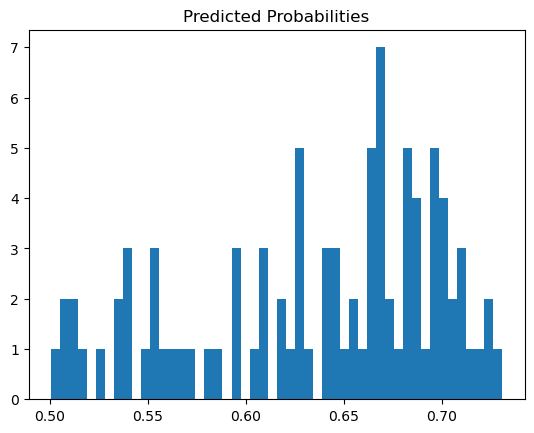

In [15]:
best_thresh = 0.5
best_f1 = 0.0

for t in np.arange(0.01, 1.0, 0.01):
    preds = (np.array(y_pred) > t).astype(int)
    score = f1_score(y_true, preds)
    if score > best_f1:
        best_f1 = score
        best_thresh = t

print(f"Best threshold: {best_thresh:.2f} with F1: {best_f1:.4f}")
np.unique(y_true, return_counts=True)

import matplotlib.pyplot as plt
plt.hist(torch.sigmoid(torch.tensor(y_pred)), bins=50)
plt.title("Predicted Probabilities")
plt.show()

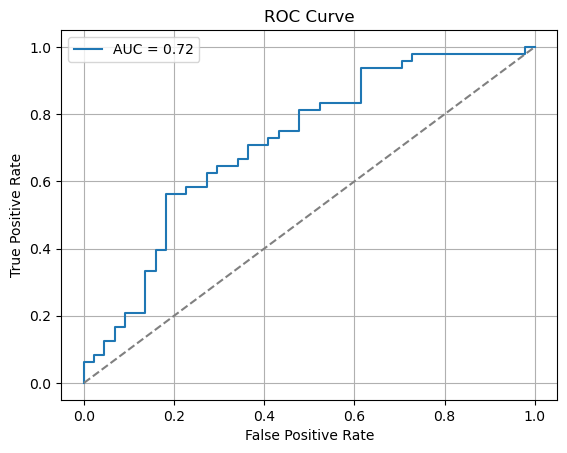

In [16]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

In [17]:
torch.save(model.state_dict(), "alexnet_ukb_qc.pth")

In [ ]:
## below implementation is for raw images

In [ ]:
base_image_directory = "/red/ruogu.fang/share/UKB/data/Eye"
base_csv_path = "/blue/ruogu.fang/pateld3/raw_combined_selected_images.csv"

df = pd.read_csv(base_csv_path)
df['image_path'] = df.apply(
    lambda row: f"{base_image_directory}/{row['source']}/{row['subject_id']}_{row['source'][:5]}_0_0.png",
    axis=1
)

df = df.drop(columns=['source'])

# Shuffle the dataframe
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df.head(5)

In [ ]:
class UKBImageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]['image_path']
        label = self.df.iloc[idx]['disease']
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.2740, 0.1463, 0.0571],
                         std=[0.3044, 0.1659, 0.0715])
])

train_df, val_df = train_test_split(df, test_size=0.25)

train_dataset = UKBImageDataset(train_df, transform=transform)
val_dataset = UKBImageDataset(val_df, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=4)

In [ ]:
# Initialize GoogLeNet model
model = models.googlenet(weights=models.GoogLeNet_Weights.IMAGENET1K_V1)

# Modify the final fully connected layer for binary classification
# googlenet.fc is the final classification layer
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 1)  # Binary classification: output logits

# Move model to device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

In [ ]:
# 5. Training Setup
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-5)

In [ ]:
epochs = 30

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device).float().unsqueeze(1)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}], Average Loss: {running_loss/len(train_loader):.4f}")

# Validation
model.eval()
y_pred, y_true = [], []
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device).float().unsqueeze(1)
        outputs = model(inputs)
        probs = torch.sigmoid(outputs).squeeze(1).cpu().numpy()
        y_pred.extend(probs)
        y_true.extend(labels.cpu().numpy())
auc = roc_auc_score(y_true, y_pred)
print("AUC:", auc)

In [ ]:
from sklearn.metrics import f1_score, accuracy_score

# Threshold predictions
binary_preds = (np.array(y_pred) > 0.5).astype(int)

# Compute F1 Score
f1 = f1_score(y_true, binary_preds)
print(f"F1 Score: {f1:.4f}")

accuracy = accuracy_score(y_true, binary_preds)
print("Accuracy:", accuracy)

In [ ]:
torch.save(model.state_dict(), "googlenet_ukb_raw.pth")